# Практика №2. Сверточная нейронная сеть (CNN)

Задача: классифицировать изображения предметов одежды на 10 категорий Fashion-MNIST.

Датасет: Fashion-MNIST, 60 000 изображений для исходного обучения и 10 000 изображений в официальной тестовой части. Размер каждого изображения - 28 * 28 пикселей, изображение одноканальное (оттенки серого). Источник: [Keras - Fashion-MNIST](https://keras.io/api/datasets/fashion_mnist/). Лицензия набора - MIT.

Сверточная нейронная сеть использует локальные фильтры, которые извлекают пространственные признаки изображения: границы, текстуры и характерные фрагменты объектов. В отличие от полносвязной сети, CNN учитывает двумерную структуру пикселей.

В работе будут выполнены проверка изображений и меток, EDA, подготовка массивов, проектирование неглубокой CNN, обучение и оценка на официальной тестовой выборке.

In [1]:
%pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

In [2]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

## 1. Загрузка данных

Fashion-MNIST загружается встроенным загрузчиком Keras. Официальную тестовую часть сохраняем отдельно и не используем при выборе модели. Исходную обучающую часть впоследствии разделим на обучающую и валидационную выборки.

In [3]:
(x_pool_raw, y_pool_raw), (x_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

print("Исходная обучающая часть:", x_pool_raw.shape, y_pool_raw.shape)
print("Официальная тестовая часть:", x_test_raw.shape, y_test.shape)
print("Тип пикселей:", x_pool_raw.dtype)
print("Диапазон пикселей:", int(x_pool_raw.min()), "—", int(x_pool_raw.max()))
display(pd.Series(y_pool_raw).map(dict(enumerate(class_names))).value_counts().to_frame("count"))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Исходная обучающая часть: (60000, 28, 28) (60000,)
Официальная тестовая часть: (10000, 28, 28) (10000,)
Тип пикселей: uint8
Диапазон пикселей: 0 — 255


,count
Ankle boot,6000
T-shirt/top,6000
Dress,6000
Pullover,6000
Sneaker,6000
Sandal,6000
Trouser,6000
Shirt,6000
Coat,6000
Bag,6000


## 2. Проверка качества данных и удаление точных дубликатов

Проверяем конечность значений пикселей, допустимость меток классов, полностью чёрные изображения и точные дубликаты в исходной обучающей части. Точные копии изображений удаляются до разделения на train и validation, чтобы одна и та же картинка не попадала сразу в обе части. Возможные необычные значения пикселей не исправляются произвольно: корректный диапазон для Fashion-MNIST - от 0 до 255.

In [4]:
valid_labels = np.isin(y_pool_raw, np.arange(len(class_names)))
finite_images = np.isfinite(x_pool_raw).all(axis=(1, 2))
non_empty_images = np.any(x_pool_raw != 0, axis=(1, 2))
valid_mask = valid_labels & finite_images & non_empty_images

print("Некорректных меток:", int((~valid_labels).sum()))
print("Изображений с NaN/inf:", int((~finite_images).sum()))
print("Полностью чёрных изображений:", int((~non_empty_images).sum()))

x_checked = x_pool_raw[valid_mask]
y_checked = y_pool_raw[valid_mask]

# Ищем точные дубликаты по полной матрице пикселей.
flat_images = x_checked.reshape(len(x_checked), -1)
_, first_indices = np.unique(flat_images, axis=0, return_index=True)
keep_indices = np.sort(first_indices)
duplicate_count = len(x_checked) - len(keep_indices)
x_pool = x_checked[keep_indices]
y_pool = y_checked[keep_indices]

print("Точных повторов изображений удалено:", int(duplicate_count))
print("Размер обучающего пула после проверки:", x_pool.shape)
print("Проверка диапазона:", int(x_pool.min()), "—", int(x_pool.max()))

Некорректных меток: 0
Изображений с NaN/inf: 0
Полностью чёрных изображений: 0
Точных повторов изображений удалено: 0
Размер обучающего пула после проверки: (60000, 28, 28)
Проверка диапазона: 0 — 255


## 3. Разведочный анализ данных (EDA)

Покажем несколько изображений с названиями классов, распределение категорий и распределение интенсивности пикселей. Для выполнения требования по корреляционной матрице рассчитаем корреляции между 64 пикселями центрального фрагмента изображения на подвыборке. Такая матрица отражает совместное изменение локальных пикселей, но не является корреляцией между готовыми признаками объектов.

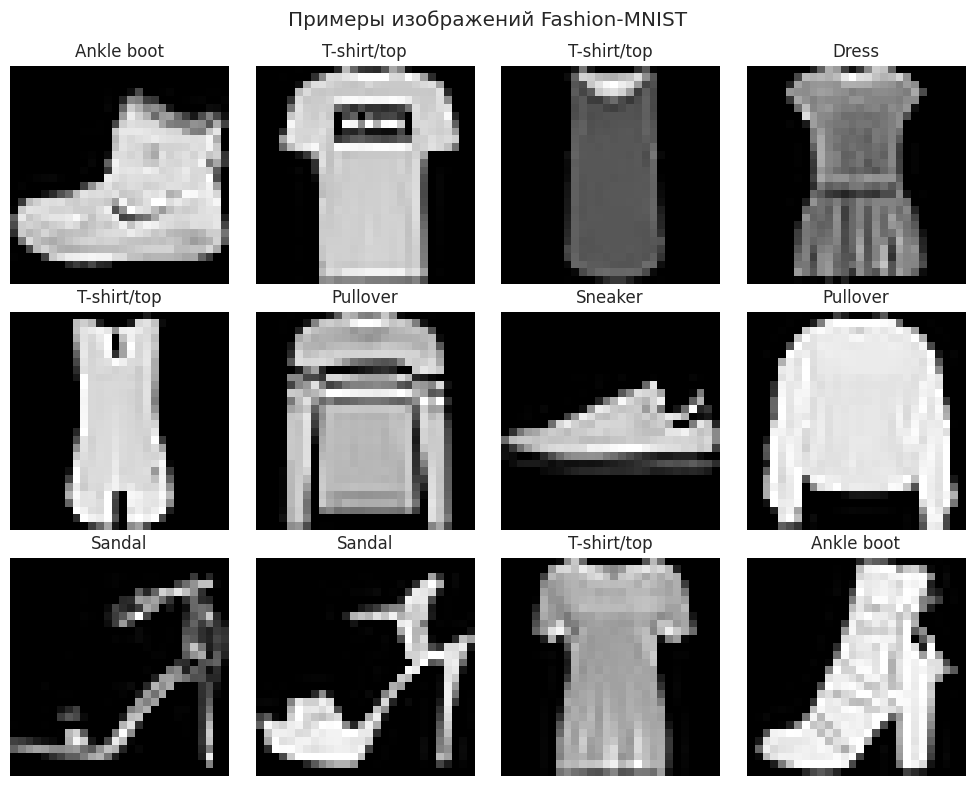

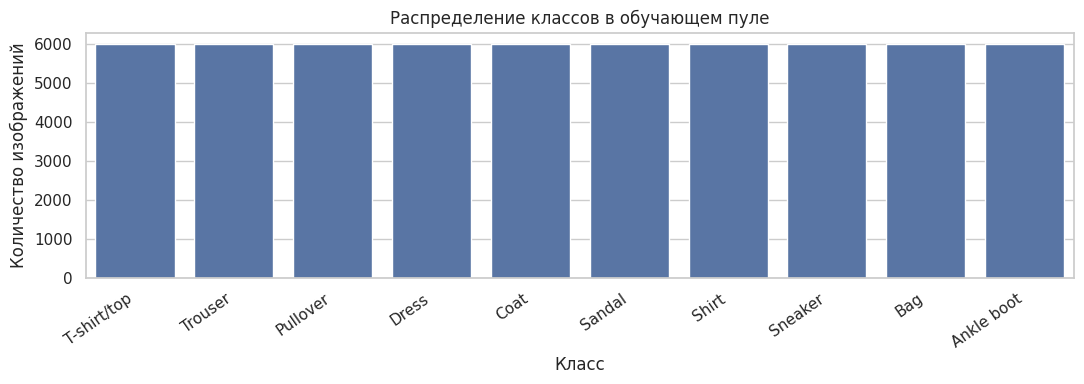

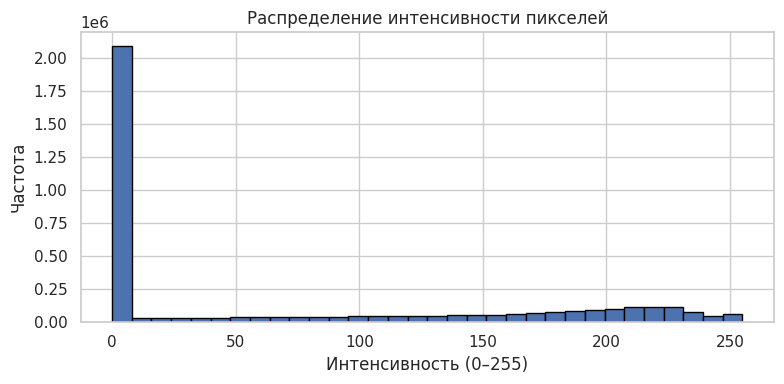

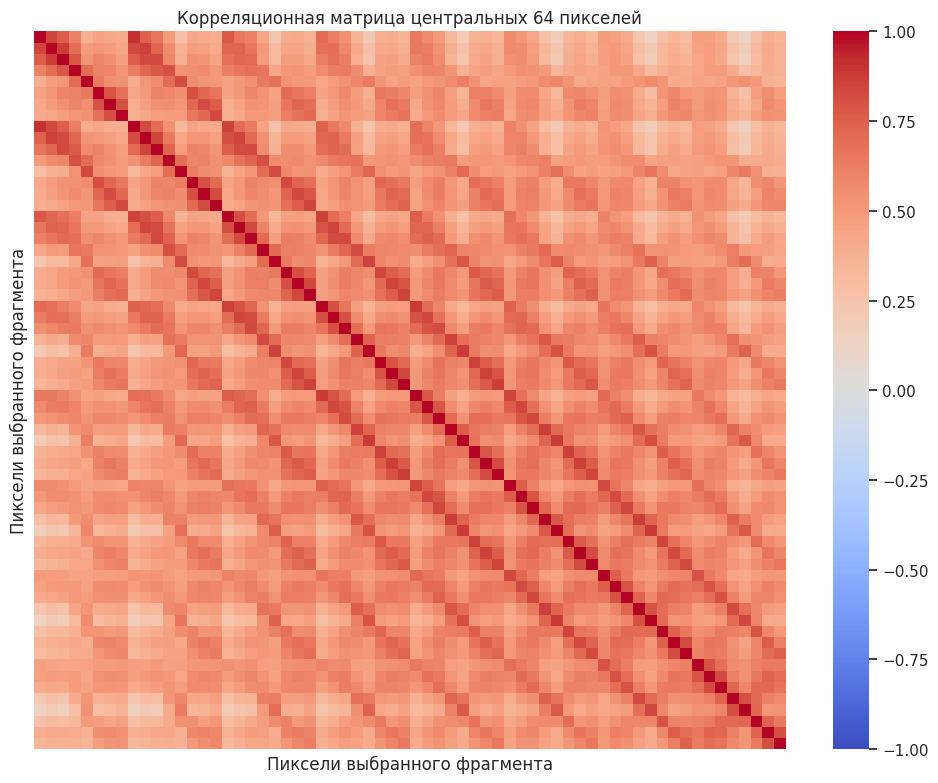

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(x_pool[index], cmap="gray")
    ax.set_title(class_names[int(y_pool[index])])
    ax.axis("off")
plt.suptitle("Примеры изображений Fashion-MNIST")
plt.tight_layout()
plt.show()

class_counts = pd.Series(y_pool).map(dict(enumerate(class_names))).value_counts().reindex(class_names)
plt.figure(figsize=(11, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Распределение классов в обучающем пуле")
plt.xlabel("Класс")
plt.ylabel("Количество изображений")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

pixel_sample = x_pool[:5000].ravel()
plt.figure(figsize=(8, 4))
plt.hist(pixel_sample, bins=32, edgecolor="black")
plt.title("Распределение интенсивности пикселей")
plt.xlabel("Интенсивность (0–255)")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

# Центральный фрагмент 8 x 8 = 64 пикселя.
flat_sample = x_pool[:5000].reshape(min(5000, len(x_pool)), -1)
pixel_indices = [row * 28 + col for row in range(10, 18) for col in range(10, 18)]
pixel_corr = np.corrcoef(flat_sample[:, pixel_indices], rowvar=False)
plt.figure(figsize=(10, 8))
sns.heatmap(pixel_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title("Корреляционная матрица центральных 64 пикселей")
plt.xlabel("Пиксели выбранного фрагмента")
plt.ylabel("Пиксели выбранного фрагмента")
plt.tight_layout()
plt.show()

## 4. Разделение выборки и нормализация изображений

Сохраняем официальную тестовую часть Fashion-MNIST. Из проверенного исходного обучающего пула выделяем 15% для validation; оставшиеся 85% используются для обучения. Получается независимая проверка на новых изображениях. Значения пикселей переводим из диапазона 0–255 в диапазон 0–1 и добавляем размерность канала, необходимую слою Conv2D.

In [6]:
x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_pool, y_pool, test_size=0.15, random_state=RANDOM_STATE, stratify=y_pool
)

print(f"Train: {len(x_train_raw)} изображений")
print(f"Validation: {len(x_val_raw)} изображений")
print(f"Test: {len(x_test_raw)} изображений (официальная часть Fashion-MNIST)")

X_train = (x_train_raw.astype("float32") / 255.0)[..., np.newaxis]
X_val = (x_val_raw.astype("float32") / 255.0)[..., np.newaxis]
X_test = (x_test_raw.astype("float32") / 255.0)[..., np.newaxis]

print("Форма тензора для CNN:", X_train.shape[1:])

Train: 51000 изображений
Validation: 9000 изображений
Test: 10000 изображений (официальная часть Fashion-MNIST)
Форма тензора для CNN: (28, 28, 1)


## 5. Проектирование сверточной нейронной сети

Архитектура содержит два сверточных блока. Слои Conv2D извлекают локальные признаки, MaxPooling2D уменьшают пространственный размер карт признаков. После Flatten данные передаются в полносвязный слой, а выходной Softmax формирует вероятности десяти классов.

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Обучение CNN

Обучение проводится на train, а после каждой эпохи качество проверяется на validation. EarlyStopping завершает обучение при отсутствии улучшений val_loss и восстанавливает веса лучшей эпохи. Официальная тестовая выборка не используется для подбора параметров.

Epoch 1/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 50s 117ms/step - accuracy: 0.7682 - loss: 0.6317 - val_accuracy: 0.8600 - val_loss: 0.3899
Epoch 2/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 79s 109ms/step - accuracy: 0.8568 - loss: 0.3956 - val_accuracy: 0.8821 - val_loss: 0.3238
Epoch 3/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 84s 115ms/step - accuracy: 0.8767 - loss: 0.3391 - val_accuracy: 0.8901 - val_loss: 0.2976
Epoch 4/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 79s 109ms/step - accuracy: 0.8868 - loss: 0.3083 - val_accuracy: 0.8958 - val_loss: 0.2797
Epoch 5/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 44s 110ms/step - accuracy: 0.8950 - loss: 0.2861 - val_accuracy: 0.9002 - val_loss: 0.2700
Epoch 6/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 81s 109ms/step - accuracy: 0.9025 - loss: 0.2650 - val_accuracy: 0.9023 - val_loss: 0.2630
Epoch 7/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 44s 110ms/step - accuracy: 0.9066 - loss: 0.2504 - val_accuracy: 0.9053 - val_loss: 0.2510
Epoch 8/20
399/399 ━━━━━━━━━━━━━━━━━━━━ 81s 109ms/step - accuracy: 0.9128 - loss: 0

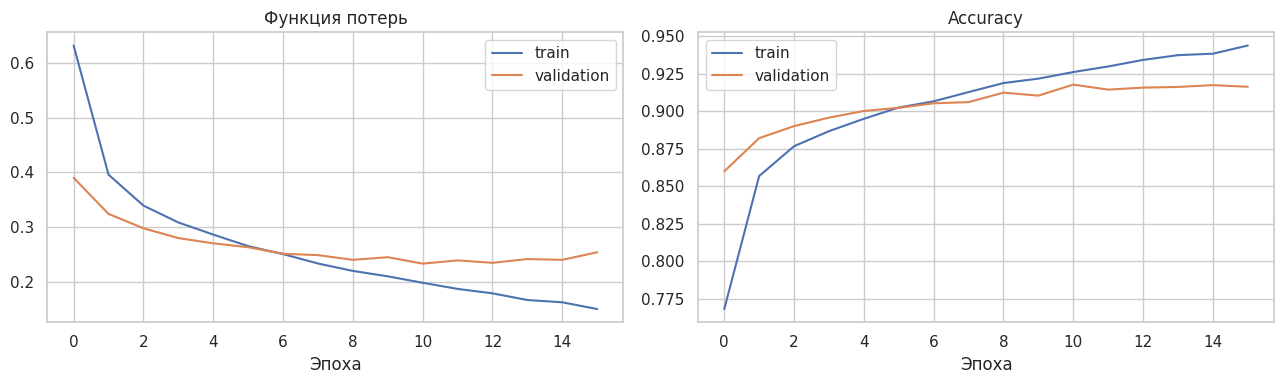

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1,
)

history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["loss"], label="train")
axes[0].plot(history_df["val_loss"], label="validation")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[1].plot(history_df["accuracy"], label="train")
axes[1].plot(history_df["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Итоговая оценка на тестовой выборке

Проверяем модель на официальной тестовой части из 10 000 изображений. Рассчитываем Accuracy, Balanced Accuracy, Precision, Recall и Macro F1. Матрица ошибок показывает распределение правильных и ошибочных классификаций между десятью категориями.

Итоговые метрики на тестовой выборке:


,value
Accuracy,0.908400
Balanced Accuracy,0.908400
Macro Precision,0.908298
Macro Recall,0.908400
Macro F1,0.907627



Отчёт по классам:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.84      0.85      1000
     Trouser       1.00      0.97      0.99      1000
    Pullover       0.87      0.85      0.86      1000
       Dress       0.89      0.92      0.91      1000
        Coat       0.82      0.92      0.86      1000
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.76      0.68      0.72      1000
     Sneaker       0.94      0.99      0.96      1000
         Bag       0.97      0.98      0.98      1000
  Ankle boot       0.99      0.94      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



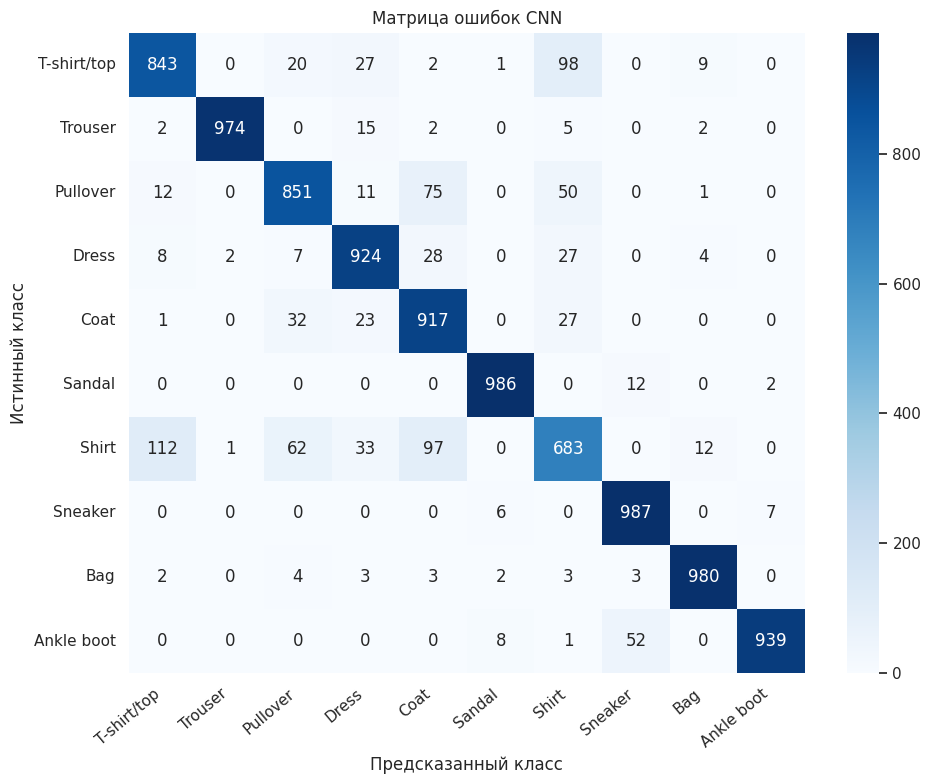

In [9]:
y_test_probability = model.predict(X_test, batch_size=256, verbose=0)
y_test_pred = np.argmax(y_test_probability, axis=1)

test_metrics = {
    "Accuracy": float(accuracy_score(y_test, y_test_pred)),
    "Balanced Accuracy": float(balanced_accuracy_score(y_test, y_test_pred)),
    "Macro Precision": float(precision_score(y_test, y_test_pred, average="macro", zero_division=0)),
    "Macro Recall": float(recall_score(y_test, y_test_pred, average="macro", zero_division=0)),
    "Macro F1": float(f1_score(y_test, y_test_pred, average="macro", zero_division=0)),
}

print("Итоговые метрики на тестовой выборке:")
display(pd.Series(test_metrics, name="value").to_frame())
print("\nОтчёт по классам:")
print(classification_report(y_test, y_test_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Матрица ошибок CNN")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Примеры предсказаний и сохранение модели

Выведем несколько примеров с истинной и предсказанной категорией. Затем сохраним модель и фактические метрики в artifacts/.

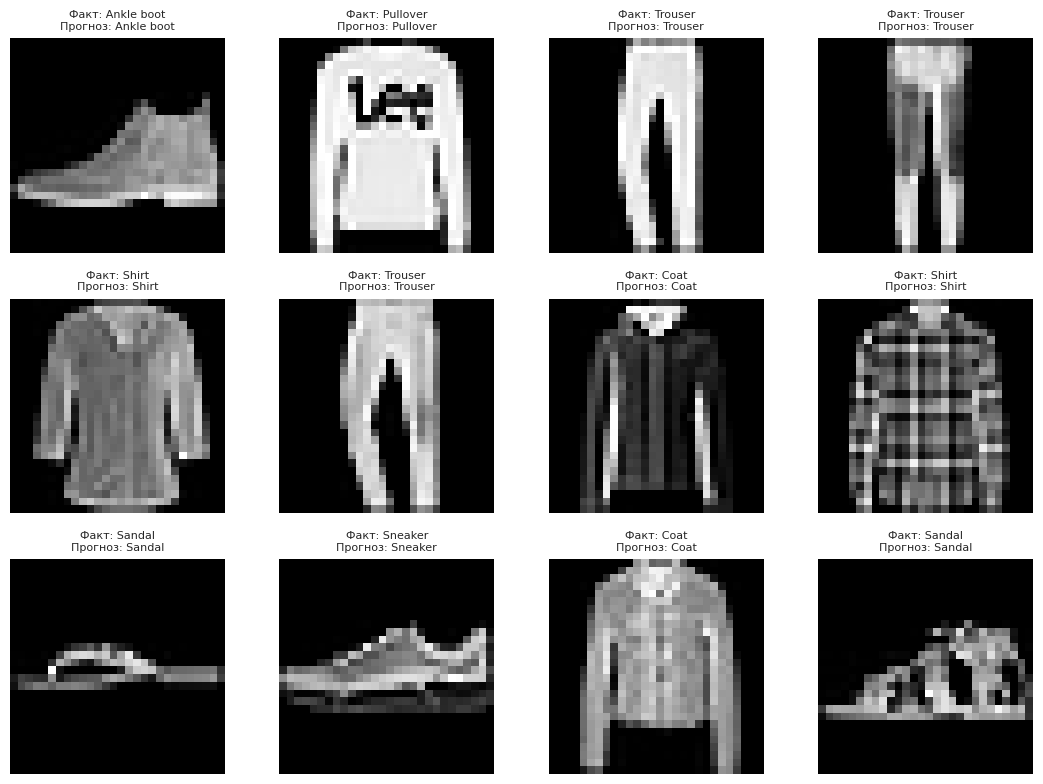

Модель и метрики сохранены в папку artifacts/


In [10]:
example_count = 12
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[index].squeeze(), cmap="gray")
    predicted_name = class_names[int(y_test_pred[index])]
    actual_name = class_names[int(y_test[index])]
    ax.set_title(f"Факт: {actual_name}\nПрогноз: {predicted_name}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)
model.save(artifact_dir / "cnn_fashion_mnist.keras")

with (artifact_dir / "cnn_fashion_mnist_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        {
            "test_metrics": test_metrics,
            "class_names": class_names,
            "input_shape": [28, 28, 1],
            "random_state": RANDOM_STATE,
        },
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Модель и метрики сохранены в папку artifacts/")